# BCSE331P – Exploratory Data Analysis
## Assessment 7: 1-D, 2-D and N-D Analysis
**Dataset:** `recid.csv` (1445 rows; columns: rownames, black, alcohol, drugs, super, married, felon, workprg, property, person, priors, educ, rules, age, tserved, follow, durat, cens, ldurat).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/recid.csv"

In [2]:
from scipy import stats

**Q1. Load the dataset**

In [3]:
df = pd.read_csv(URL)

In [4]:
# readable labels for the 0/1 coded columns (used for categorical analysis)
df["race"] = df["black"].map({1: "Black", 0: "Other"})
df["felon_status"] = df["felon"].map({1: "Felon", 0: "Non-felon"})
df["supervised"] = df["super"].map({1: "Supervised", 0: "Unsupervised"})
df["marital"] = df["married"].map({1: "Married", 0: "Single"})
df["offense"] = np.select([df["property"] == 1, df["person"] == 1], ["Property", "Person"], "Other")

In [5]:
num_vars = ["priors", "educ", "rules", "age", "tserved", "follow", "durat"]
df.head()

,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,...,tserved,follow,durat,cens,ldurat,race,felon_status,supervised,marital,offense
0,1,0,1,0,1,1,0,1,0,0,...,30,72,72,1,4.276666,Other,Non-felon,Supervised,Married,Other
1,2,1,0,0,1,0,1,1,1,0,...,19,75,75,1,4.317488,Black,Felon,Supervised,Single,Property
2,3,0,0,0,0,0,0,1,1,0,...,27,81,9,0,2.197225,Other,Non-felon,Unsupervised,Single,Property
3,4,0,0,1,1,0,1,1,1,0,...,38,76,25,0,3.218876,Other,Felon,Supervised,Single,Property
4,5,0,0,1,1,0,0,0,0,0,...,4,81,81,1,4.394449,Other,Non-felon,Supervised,Single,Other


**Q2 & Q3. Summary statistics stored in a single data.frame**  
(Skewness / Kurtosis via `scipy.stats`; kurtosis is *excess* kurtosis)

In [6]:
x = df[num_vars]
summary_df = pd.DataFrame({
    "Mean": x.mean(), "Median": x.median(), "Minimum": x.min(), "Maximum": x.max(), "Range": x.max() - x.min(),
    "Variance": x.var(), "Std Dev": x.std(), "IQR": x.quantile(.75) - x.quantile(.25),
    "Skewness": x.apply(stats.skew), "Kurtosis": x.apply(stats.kurtosis)}).round(3)
summary_df

,Mean,Median,Minimum,Maximum,Range,Variance,Std Dev,IQR,Skewness,Kurtosis
priors,1.432,0.0,0,28,28,8.125,2.850,2.0,3.991,22.808
educ,9.702,10.0,1,19,18,5.961,2.442,3.0,-0.532,1.291
rules,1.185,0.0,0,27,27,5.269,2.295,1.0,4.097,25.974
age,345.436,307.0,198,933,735,14653.232,121.051,137.0,1.488,2.076
tserved,19.182,12.0,0,219,219,439.480,20.964,19.0,3.408,18.637
follow,74.886,74.0,70,81,11,12.254,3.501,6.0,0.232,-1.206
durat,55.372,71.0,1,81,80,745.172,27.298,49.0,-0.818,-1.049


**Q4. Frequency & relative frequency tables (`offense`), Pie chart and Bar plot**

,Frequency,Relative Frequency
offense,,
Other,1000,0.6920
Property,368,0.2547
Person,77,0.0533


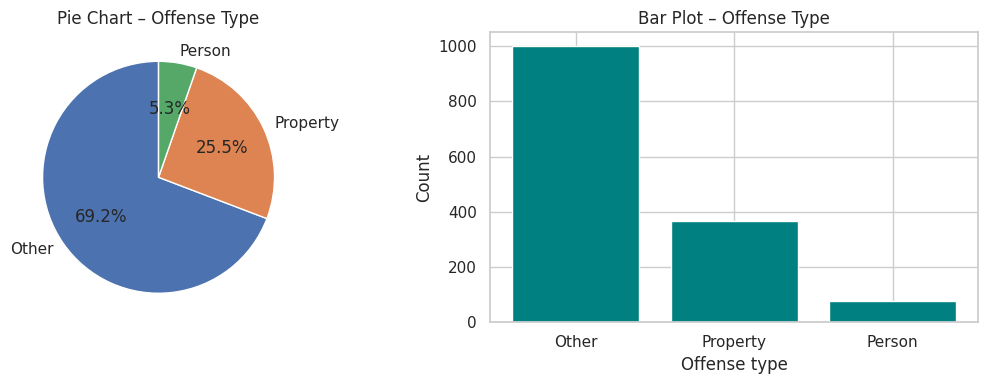

In [7]:
f = df["offense"].value_counts()
freq_table = pd.DataFrame({"Frequency": f, "Relative Frequency": (f / f.sum()).round(4)}); display(freq_table)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].pie(f, labels=f.index, autopct="%1.1f%%", startangle=90); ax[0].set_title("Pie Chart – Offense Type")
ax[1].bar(f.index, f.values, color="teal"); ax[1].set_title("Bar Plot – Offense Type"); ax[1].set_xlabel("Offense type"); ax[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

**Q5. Binned frequency table, Histogram and Box plot (`age`)**

,Frequency
age,
"(197.265, 271.5]",466
"(271.5, 345.0]",464
"(345.0, 418.5]",206
"(418.5, 492.0]",125
"(492.0, 565.5]",74
"(565.5, 639.0]",63
"(639.0, 712.5]",28
"(712.5, 786.0]",12
"(786.0, 859.5]",4


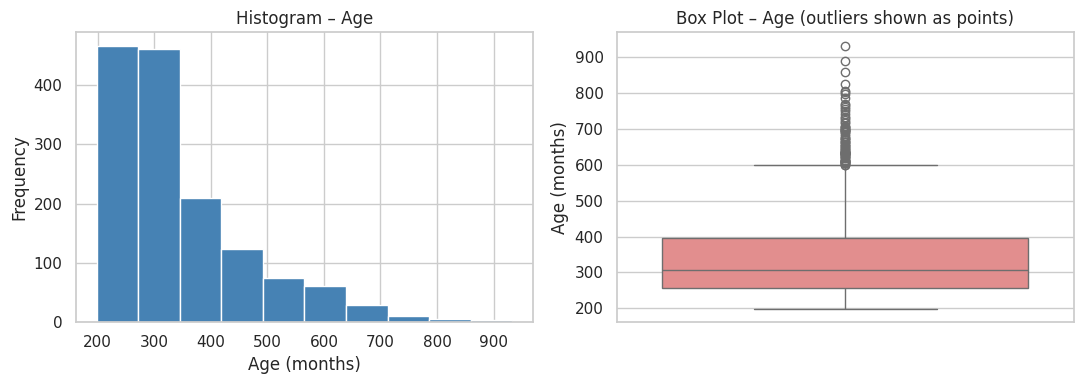

In [8]:
bins = pd.cut(df["age"], bins=10)
display(bins.value_counts().sort_index().to_frame("Frequency"))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["age"], bins=10, color="steelblue", edgecolor="white"); ax[0].set_title("Histogram – Age"); ax[0].set_xlabel("Age (months)"); ax[0].set_ylabel("Frequency")
sns.boxplot(y=df["age"], ax=ax[1], color="lightcoral"); ax[1].set_title("Box Plot – Age (outliers shown as points)"); ax[1].set_ylabel("Age (months)")
plt.tight_layout(); plt.show()

**Q6. Contingency table (`race` × `felon_status`) with row / column percentages**

In [9]:
ct = pd.crosstab(df["race"], df["felon_status"]); display(ct)
print("Row percentages (prop.table margin=1):");    display((pd.crosstab(df["race"], df["felon_status"], normalize="index") * 100).round(2))
print("Column percentages (prop.table margin=2):"); display((pd.crosstab(df["race"], df["felon_status"], normalize="columns") * 100).round(2))

felon_status,Felon,Non-felon
race,,
Black,250,451
Other,204,540


Row percentages (prop.table margin=1):


felon_status,Felon,Non-felon
race,,
Black,35.66,64.34
Other,27.42,72.58


Column percentages (prop.table margin=2):


felon_status,Felon,Non-felon
race,,
Black,55.07,45.51
Other,44.93,54.49


**Q7. Stacked and Grouped bar plots**

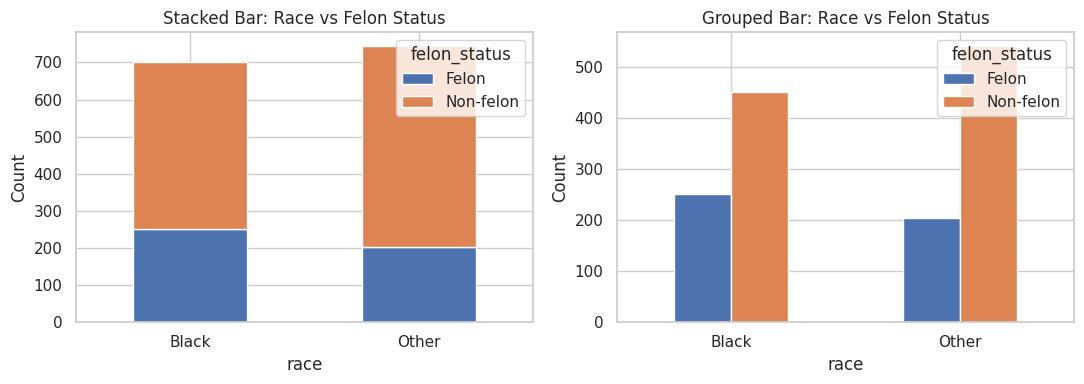

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ct.plot(kind="bar", stacked=True, ax=ax[0], rot=0); ax[0].set_title("Stacked Bar: Race vs Felon Status"); ax[0].set_ylabel("Count")
ct.plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Grouped Bar: Race vs Felon Status"); ax[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

**Q8. Mean, median, standard deviation of `tserved` by `offense` (aggregate)**

In [11]:
df.groupby("offense")["tserved"].agg(["mean", "median", "std"]).round(2)

,mean,median,std
offense,,,
Other,12.68,8.0,13.63
Person,42.49,31.0,37.34
Property,31.98,27.0,23.26


**Q9. Side-by-side box plots and Violin plot**

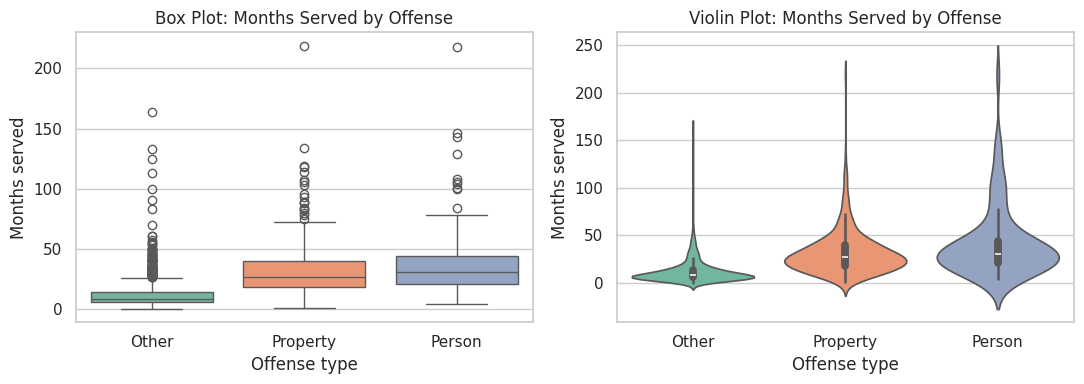

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="offense", y="tserved", ax=ax[0], palette="Set2"); ax[0].set_title("Box Plot: Months Served by Offense")
sns.violinplot(data=df, x="offense", y="tserved", ax=ax[1], palette="Set2"); ax[1].set_title("Violin Plot: Months Served by Offense")
for a in ax: a.set_xlabel("Offense type"); a.set_ylabel("Months served")
plt.tight_layout(); plt.show()

**Q10. Pearson & Spearman correlation (`age`, `tserved`) and scatter plot with regression line**

Pearson : 0.0417
Spearman: 0.0745


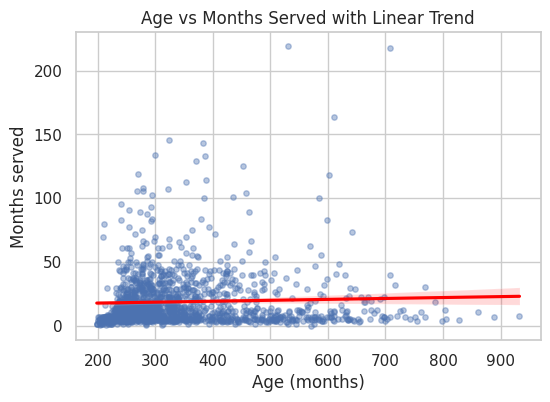

In [13]:
print("Pearson :", round(df["age"].corr(df["tserved"], method="pearson"), 4))
print("Spearman:", round(df["age"].corr(df["tserved"], method="spearman"), 4))
plt.figure(figsize=(6,4))
sns.regplot(data=df, x="age", y="tserved", scatter_kws={"alpha": .4, "s": 15}, line_kws={"color": "red"})
plt.title("Age vs Months Served with Linear Trend"); plt.xlabel("Age (months)"); plt.ylabel("Months served"); plt.show()

**Q11. Two categorical (`race`, `felon_status`) + one numerical (`tserved`)**

mean    std
race  felon_status              
Black Felon         35.44  27.40
      Non-felon     13.06  12.46
Other Felon         33.32  25.22
      Non-felon     11.43  13.09

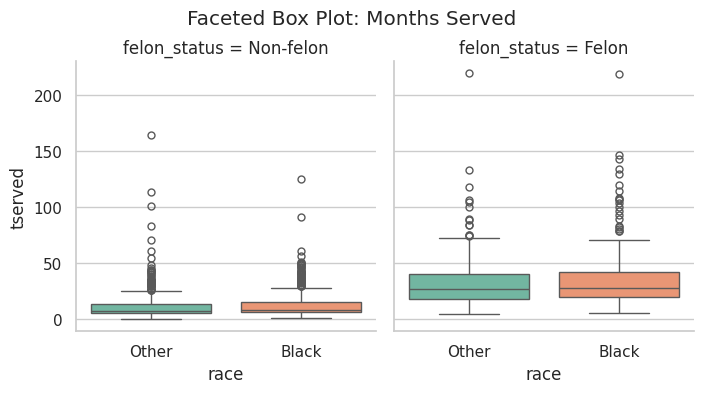

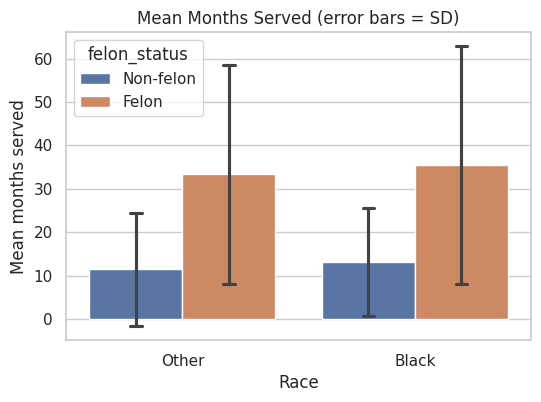

In [14]:
display(df.groupby(["race", "felon_status"])["tserved"].agg(["mean", "std"]).round(2))
sns.catplot(data=df, x="race", y="tserved", col="felon_status", kind="box", height=4, aspect=.9, palette="Set2")
plt.subplots_adjust(top=.85); plt.suptitle("Faceted Box Plot: Months Served"); plt.show()

plt.figure(figsize=(6,4))
sns.barplot(data=df, x="race", y="tserved", hue="felon_status", errorbar="sd", capsize=.1)
plt.title("Mean Months Served (error bars = SD)"); plt.xlabel("Race"); plt.ylabel("Mean months served"); plt.show()

**Q12. One categorical (`race`) + two numerical (`age`, `tserved`)**

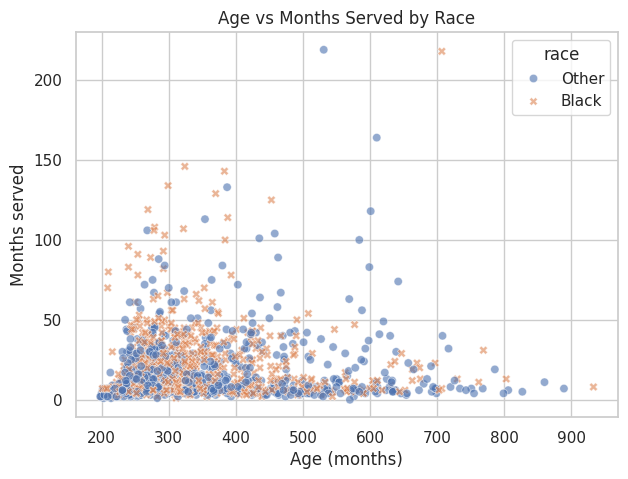


Correlation matrix for race = Black
           age  tserved
age      1.000   -0.002
tserved -0.002    1.000

Correlation matrix for race = Other
           age  tserved
age      1.000    0.089
tserved  0.089    1.000


In [15]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="age", y="tserved", hue="race", style="race", alpha=.6)
plt.title("Age vs Months Served by Race"); plt.xlabel("Age (months)"); plt.ylabel("Months served"); plt.show()

for r, g in df.groupby("race"):
    print(f"\nCorrelation matrix for race = {r}"); print(g[["age", "tserved"]].corr().round(3))

**Q13. Full correlation matrix and Heatmap (≥ 3 numerical features)**

,priors,educ,rules,age,tserved,follow,durat
priors,1.00,-0.18,0.05,0.42,0.17,-0.03,-0.14
educ,-0.18,1.00,0.01,-0.27,-0.05,0.04,0.02
rules,0.05,0.01,1.00,-0.14,0.51,-0.02,-0.18
age,0.42,-0.27,-0.14,1.00,0.04,-0.03,0.10
tserved,0.17,-0.05,0.51,0.04,1.00,-0.04,-0.19
follow,-0.03,0.04,-0.02,-0.03,-0.04,1.00,0.06
durat,-0.14,0.02,-0.18,0.10,-0.19,0.06,1.00


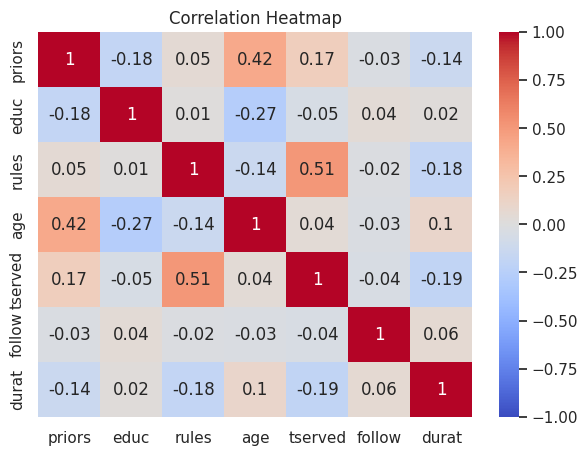

In [16]:
corr = df[num_vars].corr().round(2); display(corr)
plt.figure(figsize=(7,5)); sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap"); plt.show()

**Q14. Pairs plot / Scatterplot matrix**

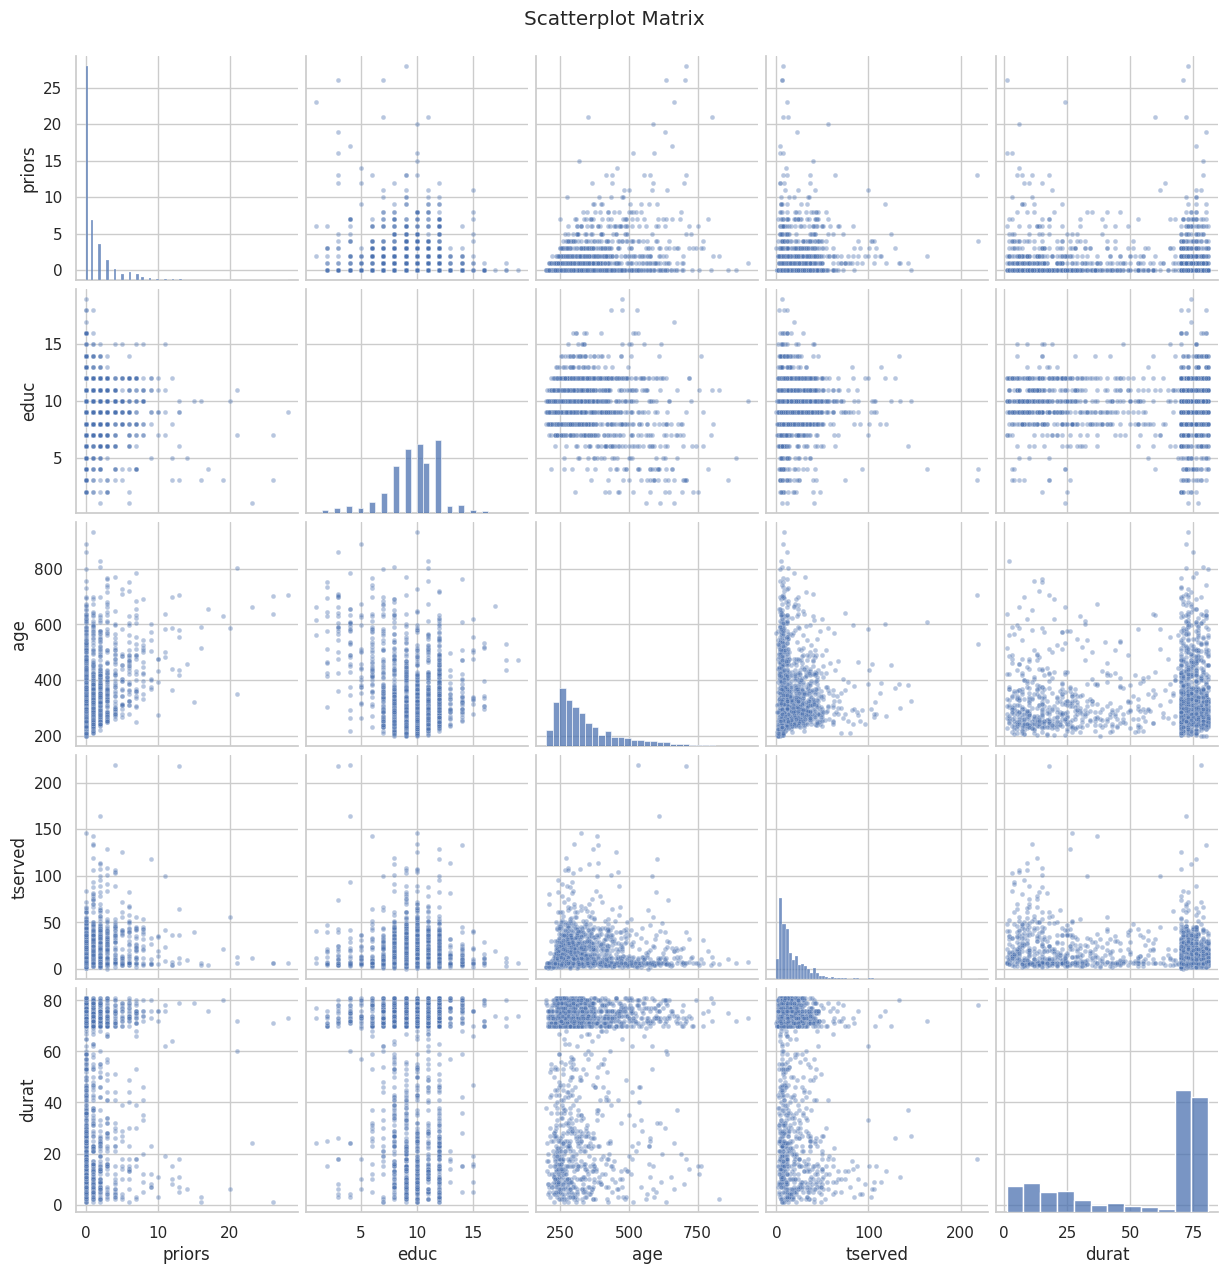

In [17]:
g = sns.pairplot(df, vars=["priors", "educ", "age", "tserved", "durat"], diag_kind="hist", plot_kws={"alpha": .4, "s": 12})
g.fig.suptitle("Scatterplot Matrix", y=1.02); plt.show()